# TwinGuard-SD-IoT — part 3: the TwinGuard safety engine

Implements and evaluates TwinGuard on top of the trained twin, **without retraining anything**. Input: the saved
predictions of `TwinGuard_experiments.ipynb` (`results/preds/`, 5 seeds per model) and the graph pipeline
(`data/processed/graph_pipeline.npz`, for timestamps and the current link state). Runs on a CPU in about a minute.

**What TwinGuard does at every decision epoch $t$ (every 15 s)** — Algorithm 1 of the paper, for the no-op action:
1. **Fidelity check.** A score $\Phi_t \in [0,1]$ combines four run-time signals (tracking error, coverage gap,
   ensemble disagreement, missing measurements). If $\Phi_t < \Phi_{\min}$: **abstain** — the twin is not trusted
   and the safe fallback acts.
2. **SLA verification.** Conformal upper bounds $U$ on RTT and loss (split conformal, adapted online with ACI).
   If $U^{\mathrm{RTT}} \le \mathrm{RTT}_{\max}$ and $U^{\mathrm{PLR}} \le \mathrm{PLR}_{\max}$: **OK** (no
   intervention needed); otherwise: **intervene**.
3. **Update.** When the outcome is measured (one epoch later), the ACI level and the fidelity history are updated.

TwinGuard is implemented as an **online gate** (`TwinGuard` class, Section 4) that processes epochs in time order
and can only use information available at decision time. A second, independent **vectorized** implementation
(Section 5) must reproduce its verdicts exactly; the notebook stops if they differ.

**Protocol (no test data is used for any choice).** The calibration split (D1, never used for training) is cut in
two halves: **cal-A** provides the conformal scores; **cal-B** fixes the reference level of each fidelity signal and
the threshold $\Phi_{\min}$. $H$ (5 min) and the ACI step $\gamma$ are fixed a priori and varied in the
sensitivity study. D1 test, the quiet D1 segment, D3 (moderate shift), and D2 (severe shift) are test data.

**Sections**
1. Setup and data
2. Conformity scores and conformal quantile
3. Fidelity signals
4. TwinGuard (online implementation of Algorithm 1) and calibration
5. Verification: independent implementation and guarantee checks
6. Coverage of the bounds (Section 6.2)
7. Gate verdicts scored against outcomes (Table 5)
8. Behaviour under shift (coverage, fidelity, verdicts)
9. Ablations and sensitivity
10. Proactive detection
11. Summary of the numbers used in the paper

## 1. Setup and data

In [1]:
import json
from collections import deque
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRED_DIR = ROOT / "results" / "preds"
PIPE = ROOT / "data" / "processed" / "graph_pipeline.npz"
OUT = ROOT / "results" / "twinguard"; OUT.mkdir(parents=True, exist_ok=True)

# ---- settings (fixed a priori; the sensitivity study varies H, GAMMA, the budgets, and EPS)
RTT_MAX, PLR_MAX, EPS = 10.0, 1.0, 0.05          # SLA budgets (ms, %) and risk tolerance
H = 20                                           # fidelity look-back: 20 epochs = 5 min (= input window W)
GAMMA = 0.005                                    # ACI step size (Gibbs & Candes, 2021)
ABSTAIN_BUDGET = 0.05                            # Phi_min: abstain on at most 5% of in-distribution epochs (cal-B)
N_BOOT, BLOCK = 300, 40                          # moving-block bootstrap (40 epochs = 10 min)
TEST_SPLITS = ["test_D1", "D1_quiet", "D3", "D2"]
STEP_S = 15
OK, ACT, ABST = 0, 1, 2                          # verdicts
SIGNALS = ["error", "coverage", "novelty", "missing"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
print("root:", ROOT)

root: <project root>


In [2]:
pipe = np.load(PIPE)
META = {}                                         # per split: timestamps of decision epochs, current link state
for split in ["cal", *TEST_SPLITS]:
    ts, cur_v, k = [], [], 0
    while f"{split}_t_end_{k}" in pipe.files:
        t_end, T, V = pipe[f"{split}_t_end_{k}"], pipe[f"{split}_ts_{k}"], pipe[f"{split}_V_{k}"]
        raw = V[..., [0, 2]]                                          # rtt (ms), packet loss (%)
        ff = pd.DataFrame(raw.reshape(len(raw), -1)).ffill().to_numpy().reshape(raw.shape)
        state = (ff[..., 0] > RTT_MAX) | (ff[..., 1] > PLR_MAX)        # last measured SLA state (fallback / B1)
        ts.append(T[t_end]); cur_v.append(state[t_end]); k += 1
    META[split] = {"ts": np.concatenate(ts), "cur_v": np.concatenate(cur_v)}

def load(split, model="GNNTwin"):
    z = np.load(PRED_DIR / f"{model}_{split}.npz")
    Q = z["Q"].astype(np.float32)                                     # [S, N, L, H, M, 3] log1p quantiles
    d = {"q": Q.mean(0),                                              # ensemble quantiles   [N, L, H, M, 3]
         "sd": Q[..., 0, 1].std(0),                                   # ensemble disagreement (RTT median) [N, L, H]
         "p": z["P"].astype(np.float32).mean(0),                      # violation probability [N, L, H]
         "y": z["Y"], "ym": z["Ym"], "v": z["V"], "lab": z["Lab"], **META[split]}
    assert len(d["ts"]) == len(d["y"]), split
    assert np.array_equal(np.isnan(d["y"][..., 0]), ~d["ym"]), split   # missing RTT <=> missing record
    return d

DATA = {s: load(s) for s in ["cal", *TEST_SPLITS]}
for s, d in DATA.items():
    print(f"{s:9s} epochs={len(d['y']):6d}  measured={100*d['ym'][:, :, 0].mean():5.1f}%  "
          f"violations={100*np.nanmean(d['v'][:, :, 0]):5.2f}%  span={(d['ts'][-1]-d['ts'][0])/3600:5.1f} h")

cal = DATA["cal"]; n_cal = len(cal["y"]); half = n_cal // 2
cut = lambda d, sl: {k: (v[sl] if isinstance(v, np.ndarray) and len(v) == n_cal else v) for k, v in d.items()}
CAL_A, CAL_B = cut(cal, slice(0, half)), cut(cal, slice(half, None))
print(f"cal-A: {half} epochs, cal-B: {n_cal - half} epochs")

cal       epochs=  2189  measured= 76.4%  violations= 1.88%  span=  9.1 h
test_D1   epochs=  2189  measured= 73.5%  violations= 1.85%  span=  9.1 h
D1_quiet  epochs=  2858  measured= 91.4%  violations= 0.59%  span= 11.9 h
D3        epochs= 13163  measured= 76.2%  violations= 5.17%  span= 55.9 h
D2        epochs=  3586  measured= 77.3%  violations=31.64%  span= 16.1 h
cal-A: 1094 epochs, cal-B: 1095 epochs


## 2. Conformity scores and conformal quantile
For a link at horizon $\Delta = 15$ s, the twin gives log-scale 0.95 quantiles $\hat q^{\mathrm{RTT}}$ and
$\hat q^{\mathrm{PLR}}$. One score covers both SLA metrics,
$$s = \max\big(\log(1+\mathrm{RTT}) - \hat q^{\mathrm{RTT}},\; \log(1+\mathrm{PLR}) - \hat q^{\mathrm{PLR}}\big),$$
so that with a margin $\hat Q$ the bounds are $U^{m} = \exp(\hat q^{m} + \hat Q) - 1$ and $\{s \le \hat Q\}$ is the
event that both bounds hold. The gate approves when both bounds are within budget, i.e. when the **slack**
$\min\big(\log(1+\mathrm{RTT}_{\max}) - \hat q^{\mathrm{RTT}}, \log(1+\mathrm{PLR}_{\max}) - \hat q^{\mathrm{PLR}}\big) \ge \hat Q$.
An approved link can then only violate the SLA if its bound fails (checked in Section 5).

The conformal margin at level $\alpha$ is the $\lceil (n+1)(1-\alpha) \rceil$-th smallest of the $n$ cal-A scores,
and $+\infty$ (never approve) when $\alpha \le 1/(n+1)$.

In [3]:
def scores(d, h=0):
    y = d["y"][:, :, h]; q95 = d["q"][:, :, h, :, 2]
    s = np.maximum(np.log1p(np.clip(y[..., 0], 0, None)) - q95[..., 0],
                   np.log1p(np.clip(y[..., 2], 0, None)) - q95[..., 2])
    return np.where(d["ym"][:, :, h], s, np.nan)                       # [N, L]; NaN = outcome missing

def slack(d, h=0, rtt_max=RTT_MAX, plr_max=PLR_MAX, q_idx=2):
    q = d["q"][:, :, h, :, q_idx]
    return np.minimum(np.log1p(rtt_max) - q[..., 0], np.log1p(plr_max) - q[..., 2])

def violated(d, h=0, rtt_max=RTT_MAX, plr_max=PLR_MAX):
    y = d["y"][:, :, h]
    v = ((y[..., 0] > rtt_max) | (y[..., 2] > plr_max)).astype(np.float32)
    return np.where(d["ym"][:, :, h], v, np.nan)                        # NaN = outcome missing

class Conformal:
    def __init__(self, cal_scores):
        self.s = np.sort(cal_scores[~np.isnan(cal_scores)]); self.n = len(self.s)
    def q(self, alpha):
        if alpha <= 1.0 / (self.n + 1):
            return np.inf
        k = int(np.ceil((self.n + 1) * (1 - alpha)))
        return self.s[min(max(k, 1), self.n) - 1]

_v = violated(DATA["test_D1"]); _ref = DATA["test_D1"]["v"][:, :, 0]; _m = ~np.isnan(_ref)
assert (np.nan_to_num(_v[_m]) == _ref[_m]).all(), "SLA definition differs from the training labels"
CP = Conformal(scores(CAL_A))
Q_STATIC = float(CP.q(EPS))
print(f"n = {CP.n} cal-A scores; static margin Q = {Q_STATIC:.4f} (bounds scale 1+value by {np.exp(Q_STATIC):.3f})")

n = 10850 cal-A scores; static margin Q = 0.0241 (bounds scale 1+value by 1.024)


## 3. Fidelity signals
Computed over the last $H$ epochs from information available at decision time:
* **Tracking error** $e_t$: mean $|\log(1+\mathrm{RTT}) - \hat q_{0.5}|$ over measured outcomes;
* **Coverage gap** $c_t$: share of measured outcomes above the *static* conformal bound (a twin-quality signal that
  ACI cannot mask by widening its bound);
* **Novelty** $\omega_t$: mean disagreement of the five ensemble members (std of their RTT medians); it needs no
  outcome, so its window includes the current epoch and it reacts first;
* **Missing measurements** $\bar m_t$: share of unmeasured link records.

Each signal $x$ is compared with its reference $r_x$, the 95th percentile of the same statistic on cal-B, and
turned into a normalized excess $\tilde x = \min(1, \max(0, (x - r_x)/r_x))$: 0 while the signal is within its
in-distribution range, 1 once it is twice its reference. Then
$$\Phi_t = (1-\tilde e_t)(1-\tilde c_t)(1-\tilde\omega_t)(1-\tilde m_t).$$
$\Phi_{\min}$ is the 5th percentile of $\Phi_t$ on cal-B, so TwinGuard abstains on at most 5% of in-distribution
epochs.

In [4]:
def excess(x, r):
    return min(1.0, max(0.0, (x - r) / r))

## 4. TwinGuard: online implementation of Algorithm 1
One object per deployment. At each epoch, `decide()` sees only the twin's predictions for the current window;
`observe()` is called afterwards with the measured outcome of that epoch, which in reality arrives 15 s later,
before the next decision. The ACI level is updated at every epoch, including abstained ones, because the bound
is still computed and checked against the outcome.

In [5]:
class TwinGuard:
    def __init__(self, cp, ref=None, phi_min=0.0, eps=EPS, gamma=GAMMA, H=H, use=SIGNALS, conformal="aci",
                 rtt_max=RTT_MAX, plr_max=PLR_MAX, q_static=None):
        self.cp, self.ref, self.phi_min, self.eps, self.gamma, self.H = cp, ref, phi_min, eps, gamma, H
        self.use, self.aci = list(use), conformal == "aci"
        self.budget = (np.log1p(rtt_max), np.log1p(plr_max))
        self.q_static = Q_STATIC if q_static is None else q_static
        self.alpha = eps
        self.hist = deque(maxlen=H)          # past epochs: (n measured, sum |error|, n static-bound failures, n missing, n links)
        self.nov = deque(maxlen=H)           # ensemble disagreement, current epoch included

    def signals(self):
        n = sum(h[0] for h in self.hist); links = sum(h[4] for h in self.hist)
        return {"error": sum(h[1] for h in self.hist) / n if n else 0.0,
                "coverage": sum(h[2] for h in self.hist) / n if n else 0.0,
                "novelty": float(np.mean(self.nov)),
                "missing": sum(h[3] for h in self.hist) / links if links else 0.0}

    def decide(self, q95, sd):
        # q95: [L, 3] log-scale 0.95 quantiles (rtt, jitter, loss); sd: [L] ensemble disagreement
        self.nov.append(float(sd.mean()))
        self.sig = self.signals()
        # step 1: fidelity check
        self.phi = 1.0
        for k in SIGNALS:
            if k in self.use:
                self.phi *= 1.0 - excess(self.sig[k], self.ref[k])
        # step 2: SLA verification with the (adaptive) conformal margin
        self.margin = self.cp.q(self.alpha) if self.aci else self.cp.q(self.eps)
        slack_ = np.minimum(self.budget[0] - q95[:, 0], self.budget[1] - q95[:, 2])
        verdict = np.where(slack_ >= self.margin, OK, ACT)
        if self.use and self.phi < self.phi_min:
            verdict[:] = ABST                    # twin not trusted: the fallback acts
        return verdict

    def observe(self, y, measured, q95, q50_rtt):
        # step 3: outcome of this epoch (raw units), measured: [L] bool
        o = measured
        lr = np.log1p(np.clip(y[:, 0], 0, None)); lp = np.log1p(np.clip(y[:, 2], 0, None))
        s = np.maximum(lr - q95[:, 0], lp - q95[:, 2])
        if o.any() and self.aci:
            self.alpha += self.gamma * (self.eps - np.mean(s[o] > self.margin))
        self.hist.append((int(o.sum()), float(np.abs(lr - q50_rtt)[o].sum(dtype=np.float64)), int((s[o] > self.q_static).sum()),
                          int((~o).sum()), len(o)))

def run_twinguard(d, **kw):
    tg = TwinGuard(CP, **kw); N, L = d["y"].shape[:2]
    verdict = np.empty((N, L), int); phi, margin = np.empty(N), np.empty(N); sig = np.empty((N, len(SIGNALS)))
    for t in range(N):
        q95 = d["q"][t, :, 0, :, 2]
        verdict[t] = tg.decide(q95, d["sd"][t, :, 0])
        phi[t], margin[t], sig[t] = tg.phi, tg.margin, [tg.sig[k] for k in SIGNALS]
        tg.observe(d["y"][t, :, 0], d["ym"][t, :, 0], q95, d["q"][t, :, 0, 0, 1])
    return {"verdict": verdict, "phi": phi, "margin": margin, "sig": sig}

# ---- calibration on cal-B: signal references, then Phi_min
_r = run_twinguard(CAL_B, ref={k: 1.0 for k in SIGNALS}, use=[])
REF = {k: float(np.percentile(_r["sig"][H:, i], 95)) for i, k in enumerate(SIGNALS)}
PHI_B = run_twinguard(CAL_B, ref=REF, phi_min=0.0)["phi"]
PHI_MIN = float(np.percentile(PHI_B, 100 * ABSTAIN_BUDGET, method="lower"))
print("signal references (95th percentile on cal-B):", {k: round(v, 4) for k, v in REF.items()})
print(f"Phi_min = {PHI_MIN:.4f}; abstention on cal-B = {np.mean(PHI_B < PHI_MIN):.3f}")

# results of TwinGuard (B5) on every test split
TG = {s: run_twinguard(DATA[s], ref=REF, phi_min=PHI_MIN) for s in TEST_SPLITS}
for s in TEST_SPLITS:
    v = TG[s]["verdict"]
    print(f"{s:9s} OK={np.mean(v == OK):.3f}  intervene={np.mean(v == ACT):.3f}  abstain={np.mean(v[:, 0] == ABST):.3f}  "
          f"mean Phi={TG[s]['phi'].mean():.3f}")

signal references (95th percentile on cal-B): {'error': 0.2433, 'coverage': 0.0797, 'novelty': 0.0346, 'missing': 0.3192}
Phi_min = 0.8573; abstention on cal-B = 0.049


test_D1   OK=0.797  intervene=0.098  abstain=0.105  mean Phi=0.959
D1_quiet  OK=0.946  intervene=0.032  abstain=0.022  mean Phi=0.988
D3        OK=0.170  intervene=0.034  abstain=0.796  mean Phi=0.441
D2        OK=0.038  intervene=0.008  abstain=0.953  mean Phi=0.142


## 5. Verification
**(a) Independent implementation.** The same gate written in vectorized form (cumulative sums over time instead of
a sequential loop) must give the same verdicts, fidelity scores, and margins on every split and for every
ablation. **(b) Guarantee checks.** Every approved link that violated the SLA must have a failed bound; the static
margin must cover at least $1-\varepsilon$ of the cal-A scores; $\Phi_{\min}$ must give at most 5% abstention on
cal-B; no decision may use a future outcome (the online class enforces this by construction).

In [6]:
def rolling_sum(x, H_, lag):
    # sum over epochs [t-H_-lag+1, t-lag]; lag=1 -> only outcomes already known at epoch t
    c = np.concatenate([[0.0], np.cumsum(x, dtype=float)])
    t = np.arange(len(x)); hi = np.clip(t - lag + 1, 0, None); lo = np.clip(hi - H_, 0, None)
    return c[hi] - c[lo], hi - lo

def aci_margins(cp, s, eps=EPS, gamma=GAMMA):
    N = len(s); Qt = np.empty(N); a = eps
    for t in range(N):
        Qt[t] = cp.q(a); o = ~np.isnan(s[t])
        if o.any():
            a = a + gamma * (eps - np.mean(s[t][o] > Qt[t]))
    return Qt

def signals_vec(d, H_=H):
    y = d["y"][:, :, 0, 0]; o = d["ym"][:, :, 0]; L = o.shape[1]; s = scores(d)
    ae = np.where(o, np.abs(np.log1p(np.clip(y, 0, None)) - d["q"][:, :, 0, 0, 1]), 0.0)
    n, _ = rolling_sum(o.sum(1), H_, 1)
    err = rolling_sum(ae.sum(1), H_, 1)[0]; cov = rolling_sum(np.nansum(s > Q_STATIC, 1) * 1.0, H_, 1)[0]
    nov_s, nov_n = rolling_sum(d["sd"][:, :, 0].mean(1), H_, 0)
    un, un_n = rolling_sum((~o).sum(1), H_, 1)
    return {"error": np.where(n > 0, err / np.maximum(n, 1), 0.0), "coverage": np.where(n > 0, cov / np.maximum(n, 1), 0.0),
            "novelty": nov_s / np.maximum(nov_n, 1), "missing": np.where(un_n > 0, un / np.maximum(un_n * L, 1), 0.0)}

def gate_vec(d, ref=None, phi_min=None, eps=EPS, gamma=GAMMA, H=H, use=SIGNALS, conformal="aci",
             rtt_max=RTT_MAX, plr_max=PLR_MAX):
    ref = REF if ref is None else ref; phi_min = PHI_MIN if phi_min is None else phi_min
    s = scores(d); N = len(s)
    Qm = aci_margins(CP, s, eps, gamma) if conformal == "aci" else np.full(N, CP.q(eps))
    verdict = np.where(slack(d, 0, rtt_max, plr_max) >= Qm[:, None], OK, ACT)
    sig = signals_vec(d, H); phi = np.ones(N)
    for k in SIGNALS:
        if k in use:
            phi = phi * (1 - np.clip((sig[k] - ref[k]) / ref[k], 0, 1))
    if use:
        verdict[phi < phi_min] = ABST
    return verdict, phi, Qm

ABL = {"B5 TwinGuard": {}, "A1 no fidelity check": {"use": []}, "A2 static conformal": {"conformal": "static"},
       "A3 no missing-measurement signal": {"use": ["error", "coverage", "novelty"]},
       "A4 no novelty signal": {"use": ["error", "coverage", "missing"]}}
checks = []
for split in TEST_SPLITS:
    for name, kw in ABL.items():
        on = TG[split] if name == "B5 TwinGuard" else run_twinguard(DATA[split], ref=REF, phi_min=PHI_MIN, **kw)
        v, phi, Qm = gate_vec(DATA[split], **kw)
        checks.append({"split": split, "config": name, "verdicts_identical": bool(np.array_equal(on["verdict"], v)),
                       "max_phi_diff": float(np.max(np.abs(on["phi"] - phi))),
                       "margins_identical": bool(np.array_equal(on["margin"], Qm))})
CHECKS = pd.DataFrame(checks); display(CHECKS); print("verdicts identical in all cases:", CHECKS.verdicts_identical.all(), "| largest Phi difference (float32 rounding):", CHECKS.max_phi_diff.max())
assert CHECKS.verdicts_identical.all() and CHECKS.margins_identical.all() and (CHECKS.max_phi_diff < 1e-6).all(), \
    "the two implementations disagree"

# guarantee checks
for split in ["cal", *TEST_SPLITS]:
    d = DATA[split]; r = TG.get(split) or run_twinguard(d, ref=REF, phi_min=PHI_MIN)
    s = scores(d); v = violated(d)
    bad = (r["verdict"] == OK) & (v == 1) & ~(s > r["margin"][:, None])
    assert not bad.any(), f"{split}: an approved violation with a valid bound"
assert np.mean(scores(CAL_A)[~np.isnan(scores(CAL_A))] <= Q_STATIC) >= 1 - EPS
assert np.mean(PHI_B < PHI_MIN) <= ABSTAIN_BUDGET + 1e-9
print("all verification checks passed: two implementations agree; approved violations only occur when the bound fails")

,split,config,verdicts_identical,max_phi_diff,margins_identical
0,test_D1,B5 TwinGuard,True,1.967485e-08,True
1,test_D1,A1 no fidelity check,True,0.000000e+00,True
2,test_D1,A2 static conformal,True,1.967485e-08,True
3,test_D1,A3 no missing-measurement signal,True,1.967485e-08,True
4,test_D1,A4 no novelty signal,True,2.217096e-08,True
5,D1_quiet,B5 TwinGuard,True,3.271239e-08,True
6,D1_quiet,A1 no fidelity check,True,0.000000e+00,True
7,D1_quiet,A2 static conformal,True,3.271239e-08,True
8,D1_quiet,A3 no missing-measurement signal,True,3.271239e-08,True
9,D1_quiet,A4 no novelty signal,True,3.271239e-08,True


verdicts identical in all cases: True | largest Phi difference (float32 rounding): 5.2977779829710414e-08
all verification checks passed: two implementations agree; approved violations only occur when the bound fails


## 6. Coverage of the bounds (Section 6.2)
Empirical coverage of the joint RTT and loss bound for the twin's raw 0.95 quantiles (B4), the static conformal
margin (A2), and the adaptive margin of TwinGuard (B5), with the median RTT bound in ms.

In [7]:
rows = []
for split in TEST_SPLITS:
    d = DATA[split]; s = scores(d); o = ~np.isnan(s); q95r = d["q"][:, :, 0, 0, 2]
    for name, Qm in [("B4 ensemble quantile (uncalibrated)", np.zeros(len(s))),
                     ("A2 static split conformal", np.full(len(s), Q_STATIC)),
                     ("B5 adaptive conformal (TwinGuard)", TG[split]["margin"])]:
        U = np.expm1(q95r + Qm[:, None])
        rows.append({"split": split, "bound": name, "coverage": (s <= Qm[:, None])[o].mean(),
                     "median_rtt_bound_ms": np.median(U[o]), "share_infinite": np.mean(np.isinf(Qm))})
COV = pd.DataFrame(rows); COV.to_csv(OUT / "coverage.csv", index=False)
display(COV.pivot(index="bound", columns="split", values="coverage")[TEST_SPLITS].round(3))
display(COV.pivot(index="bound", columns="split", values="median_rtt_bound_ms")[TEST_SPLITS].round(2))

split,test_D1,D1_quiet,D3,D2
bound,,,,
A2 static split conformal,0.953,0.957,0.878,0.632
B4 ensemble quantile (uncalibrated),0.946,0.949,0.867,0.627
B5 adaptive conformal (TwinGuard),0.950,0.952,0.947,0.948


split,test_D1,D1_quiet,D3,D2
bound,,,,
A2 static split conformal,2.61,2.69,3.02,3.58
B4 ensemble quantile (uncalibrated),2.53,2.60,2.92,3.47
B5 adaptive conformal (TwinGuard),2.58,2.64,4.15,21.64


## 7. Gate verdicts scored against outcomes (Table 5)
Compared gates (all evaluated for the no-op action, whose outcome is the observed future):
* **B1 reactive:** OK unless the link currently violates the SLA (a threshold controller);
* **B3 point forecast:** OK if the twin's *median* RTT and loss are within budget;
* **B4 uncalibrated:** OK if the twin's raw 0.95 quantiles are within budget;
* **B5 TwinGuard.**

Metrics, over (epoch, link) pairs: **false-approval rate** = P(violation | OK) on measured outcomes, and in the
**worst case** where a missing outcome after an OK counts as a violation; **missed violations** = share of
violations that received an OK; **intervention rate** (link-epochs) and **abstention rate** (epochs);
**system** metrics, where abstained epochs are decided by the fallback $\pi_{\mathrm{safe}}$ (the current measured
state). Intervals: moving-block bootstrap over epochs (blocks of 10 min).

In [8]:
def stateless(d, cfg, rtt_max=RTT_MAX, plr_max=PLR_MAX):
    if cfg == "B1":
        return np.where(d["cur_v"], ACT, OK)
    return np.where(slack(d, 0, rtt_max, plr_max, q_idx=1 if cfg == "B3" else 2) >= 0, OK, ACT)

def epoch_counts(verdict, d, rtt_max=RTT_MAX, plr_max=PLR_MAX):
    v = violated(d, 0, rtt_max, plr_max); obs = ~np.isnan(v); vio = obs & (v == 1)
    ok = verdict == OK
    fb = np.where(d["cur_v"], ACT, OK)                          # fallback on abstained epochs
    sys_ok = np.where(verdict == ABST, fb == OK, ok)
    return np.stack([(ok & obs).sum(1), (ok & vio).sum(1), ok.sum(1), (ok & (vio | ~obs)).sum(1), vio.sum(1),
                     (verdict == ACT).sum(1), (verdict == ABST).any(1), np.full(len(v), v.shape[1]),
                     (sys_ok & obs).sum(1), (sys_ok & vio).sum(1), sys_ok.sum(1)], 1).astype(float)

def summarize(c):
    S = c.sum(0); div = lambda a, b: a / b if b > 0 else np.nan
    return {"false_approval": div(S[1], S[0]), "false_approval_worst": div(S[3], S[2]),
            "missed_violations": div(S[1], S[4]), "intervention_rate": div(S[5], S[7]),
            "abstention_rate": S[6] / len(c), "system_false_approval": div(S[9], S[8]),
            "system_missed_violations": div(S[9], S[4]), "system_intervention_rate": 1 - div(S[10], S[7])}

def boot_ci(c, key, n_boot=N_BOOT, block=BLOCK, seed=0):
    rng = np.random.default_rng(seed); N = len(c); nb = int(np.ceil(N / block)); vals = []
    for _ in range(n_boot):
        st = rng.integers(0, max(1, N - block), nb)
        idx = np.concatenate([np.arange(a, min(a + block, N)) for a in st])[:N]
        vals.append(summarize(c[idx])[key])
    return np.nanpercentile(vals, [2.5, 97.5])

GATES = {"B1 reactive": lambda s: stateless(DATA[s], "B1"), "B3 twin, point forecast": lambda s: stateless(DATA[s], "B3"),
         "B4 twin, uncalibrated": lambda s: stateless(DATA[s], "B4"), "B5 TwinGuard": lambda s: TG[s]["verdict"]}
rows = []
for split in TEST_SPLITS:
    for label, fn in GATES.items():
        c = epoch_counts(fn(split), DATA[split]); lo, hi = boot_ci(c, "false_approval")
        rows.append({"split": split, "config": label, **summarize(c), "fa_lo": lo, "fa_hi": hi,
                     "missing_targets": 1 - DATA[split]["ym"][:, :, 0].mean()})
GATE = pd.DataFrame(rows); GATE.to_csv(OUT / "gate_verdicts.csv", index=False)
display(GATE[["split", "config", "false_approval", "fa_lo", "fa_hi", "false_approval_worst", "missed_violations",
              "intervention_rate", "abstention_rate"]].round(4))

,split,config,false_approval,fa_lo,fa_hi,false_approval_worst,missed_violations,intervention_rate,abstention_rate
0,test_D1,B1 reactive,0.0121,0.0105,0.0135,0.2102,0.6434,0.0979,0.0000
1,test_D1,"B3 twin, point forecast",0.0185,0.0163,0.0211,0.2787,1.0000,0.0000,0.0000
2,test_D1,"B4 twin, uncalibrated",0.0063,0.0052,0.0076,0.2135,0.3256,0.1081,0.0000
3,test_D1,B5 TwinGuard,0.0062,0.0050,0.0075,0.2075,0.2894,0.0983,0.1051
4,D1_quiet,B1 reactive,0.0036,0.0022,0.0048,0.0812,0.6000,0.0151,0.0000
5,D1_quiet,"B3 twin, point forecast",0.0059,0.0037,0.0079,0.0919,1.0000,0.0000,0.0000
6,D1_quiet,"B4 twin, uncalibrated",0.0020,0.0012,0.0028,0.0669,0.3350,0.0348,0.0000
7,D1_quiet,B5 TwinGuard,0.0019,0.0011,0.0026,0.0637,0.3100,0.0322,0.0220
8,D3,B1 reactive,0.0314,0.0301,0.0325,0.2354,0.5750,0.0849,0.0000
9,D3,"B3 twin, point forecast",0.0517,0.0482,0.0555,0.2776,1.0000,0.0000,0.0000


**System-level safety and the fallback.** Under abstention the fallback $\pi_{\mathrm{safe}}$, as defined in the
paper, acts on the current measured state, i.e. like the reactive rule B1. The next cell compares the closed loop
with that fallback, the adaptive conformal gate without fidelity check (A1), and a **conservative fallback** that
approves only when both the current state and the adaptive bound allow it. *The conservative variant was defined
after seeing the results above and is reported as a post hoc analysis.*

In [9]:
rows = []
for split in TEST_SPLITS:
    d = DATA[split]; v5 = TG[split]["verdict"]; vaci = run_twinguard(d, ref=REF, use=[])["verdict"]
    cons = np.where(v5 == ABST, np.where(~d["cur_v"] & (vaci == OK), OK, ACT), v5)
    for name, ver in [("B1 reactive", stateless(d, "B1")), ("A1 adaptive conformal, no fidelity check", vaci),
                      ("B5 with reactive fallback (as defined)", v5), ("B5 with conservative fallback (post hoc)", cons)]:
        r = summarize(epoch_counts(ver, d))
        rows.append({"split": split, "system": name, "false_approval": r["system_false_approval"],
                     "missed_violations": r["system_missed_violations"], "intervention_rate": r["system_intervention_rate"]})
FALLBACK = pd.DataFrame(rows); FALLBACK.to_csv(OUT / "fallback_posthoc.csv", index=False)
display(FALLBACK.round(3))

,split,system,false_approval,missed_violations,intervention_rate
0,test_D1,B1 reactive,0.012,0.643,0.098
1,test_D1,"A1 adaptive conformal, no fidelity check",0.006,0.326,0.109
2,test_D1,B5 with reactive fallback (as defined),0.007,0.359,0.112
3,test_D1,B5 with conservative fallback (post hoc),0.006,0.320,0.118
4,D1_quiet,B1 reactive,0.004,0.600,0.015
5,D1_quiet,"A1 adaptive conformal, no fidelity check",0.002,0.325,0.035
6,D1_quiet,B5 with reactive fallback (as defined),0.002,0.340,0.034
7,D1_quiet,B5 with conservative fallback (post hoc),0.002,0.325,0.036
8,D3,B1 reactive,0.031,0.575,0.085
9,D3,"A1 adaptive conformal, no fidelity check",0.018,0.299,0.220


Closed-loop safety and cost under shift for the four systems above (`results/twinguard/fig_fallback.png`):
false approvals (dashed line: $\varepsilon$), missed violations, and interventions.

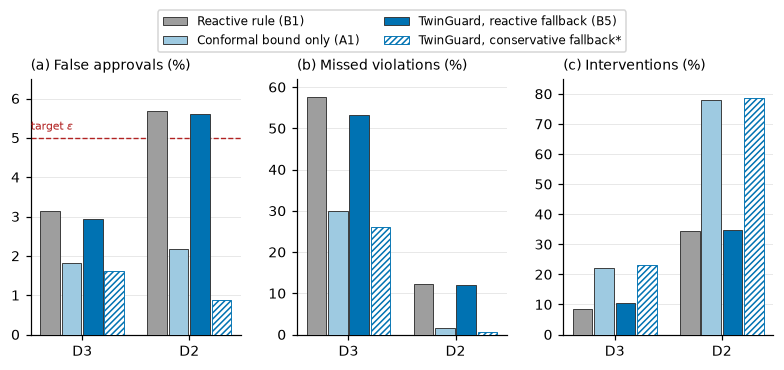

In [10]:
SHIFT = ["D3", "D2"]
systems = [("B1 reactive", "Reactive rule (B1)", "0.62", None),
           ("A1 adaptive conformal, no fidelity check", "Conformal bound only (A1)", "#9ecae1", None),
           ("B5 with reactive fallback (as defined)", "TwinGuard, reactive fallback (B5)", "#0072B2", None),
           ("B5 with conservative fallback (post hoc)", "TwinGuard, conservative fallback*", "#0072B2", "//////")]
panels = [("false_approval", "(a) False approvals (%)", 6.5), ("missed_violations", "(b) Missed violations (%)", 62),
          ("intervention_rate", "(c) Interventions (%)", 85)]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.0))
for ax, (col, title, ymax) in zip(axes, panels):
    for i, (key, label, color, hatch) in enumerate(systems):
        vals = [100 * FALLBACK[(FALLBACK.split == s) & (FALLBACK.system == key)][col].iloc[0] for s in SHIFT]
        x = np.arange(len(SHIFT)) + (i - 1.5) * 0.2
        ax.bar(x, vals, 0.184, color="white" if hatch else color, edgecolor=color if hatch else "0.2",
               hatch=hatch, lw=0.6, label=label, zorder=3)
    if col == "false_approval":
        ax.axhline(EPS * 100, color="#b22222", ls="--", lw=0.9, zorder=2)
        ax.text(-0.48, EPS * 100 + 0.12, r"target $\varepsilon$", color="#b22222", fontsize=7, va="bottom")
    ax.set_ylim(0, ymax); ax.set_xticks(range(len(SHIFT))); ax.set_xticklabels(SHIFT)
    ax.set_title(title, loc="left", fontsize=9); ax.grid(True, axis="y", color="0.9", lw=0.6); ax.set_axisbelow(True)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.12), fontsize=8)
fig.tight_layout(w_pad=2.0); fig.savefig(OUT / "fig_fallback.png", bbox_inches="tight")
plt.show()

## 8. Behaviour under shift (coverage, fidelity, verdicts)
Three figures, saved to `results/twinguard/`, each with D3 (moderate shift) on the left and D2 (severe shift) on the right:
* `fig_coverage.png`: miscoverage of the static and adaptive bounds over the last hour, against $\varepsilon$;
* `fig_fidelity.png`: fidelity score $\Phi_t$ (15-min median for readability) and $\Phi_{\min}$;
* `fig_verdicts.png`: share of verdicts per 15 min.
Gaps in the data are left blank.

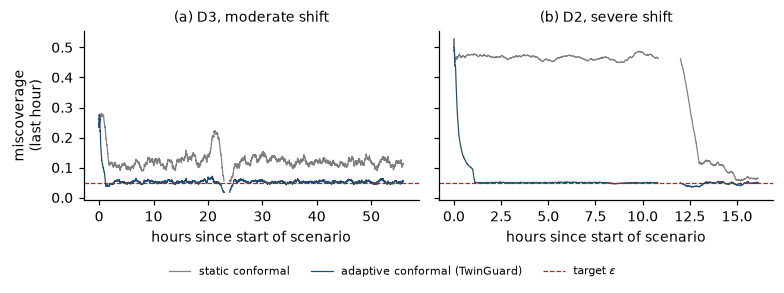

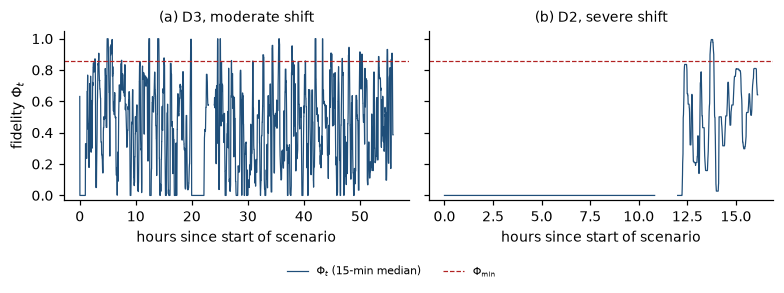

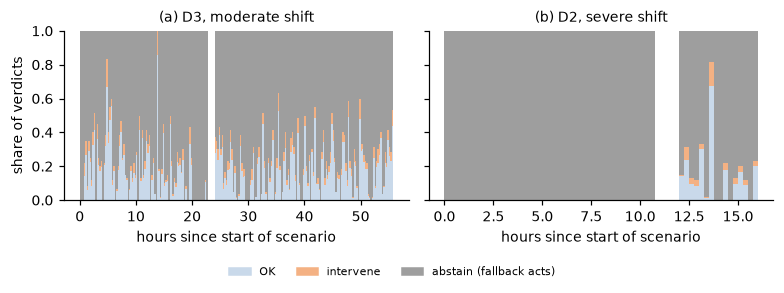

In [11]:
def gaps_to_nan(t, *ys, max_gap=4 * STEP_S):
    br = np.where(np.diff(t) > max_gap)[0] + 1
    return (np.insert(t.astype(float), br, np.nan), *[np.insert(y.astype(float), br, np.nan) for y in ys])

def rolling_rate(num, den, w):
    a, _ = rolling_sum(num, w, 0); b, _ = rolling_sum(den, w, 0)
    return np.where(b > 0, a / np.maximum(b, 1), np.nan)

SHIFT = ["D3", "D2"]; TITLES = {"D3": "(a) D3, moderate shift", "D2": "(b) D2, severe shift"}
VCOL = ["#c9d9ea", "#f4b183", "#9e9e9e"]

def panels(ylabel):
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.5), sharey=True)
    for a, s in zip(ax, SHIFT):
        a.set_title(TITLES[s], fontsize=9); a.set_xlabel("hours since start of scenario")
    ax[0].set_ylabel(ylabel)
    return fig, ax

def hours(d, t):
    return (t - d["ts"][0]) / 3600

# rolling miscoverage of the static and adaptive bounds
fig, ax = panels("miscoverage\n(last hour)")
for a, s in zip(ax, SHIFT):
    d = DATA[s]; sc = scores(d); o = ~np.isnan(sc)
    ms = rolling_rate(np.nansum(sc > Q_STATIC, 1) * 1.0, o.sum(1) * 1.0, 240)
    ma = rolling_rate(np.nansum(sc > TG[s]["margin"][:, None], 1) * 1.0, o.sum(1) * 1.0, 240)
    t, a1, a2 = gaps_to_nan(d["ts"], ms, ma)
    a.plot(hours(d, t), a1, lw=0.8, color="#7f7f7f", label="static conformal")
    a.plot(hours(d, t), a2, lw=0.8, color="#1f4e79", label="adaptive conformal (TwinGuard)")
    a.axhline(EPS, ls="--", lw=0.8, color="#b22222", label=r"target $\varepsilon$")
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, fontsize=7, frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(OUT / "fig_coverage.png", bbox_inches="tight")
plt.show()

# fidelity score
fig, ax = panels(r"fidelity $\Phi_t$")
for a, s in zip(ax, SHIFT):
    d = DATA[s]; phi = pd.Series(TG[s]["phi"]).rolling(60, min_periods=1).median().to_numpy()
    t, p = gaps_to_nan(d["ts"], phi)
    a.plot(hours(d, t), p, lw=0.8, color="#1f4e79", label=r"$\Phi_t$ (15-min median)")
    a.axhline(PHI_MIN, ls="--", lw=0.8, color="#b22222", label=r"$\Phi_{\min}$"); a.set_ylim(-0.03, 1.05)
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, fontsize=7, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(OUT / "fig_fidelity.png", bbox_inches="tight")
plt.show()

# verdicts per 15 min
fig, ax = panels("share of verdicts")
for a, s in zip(ax, SHIFT):
    d = DATA[s]; v = TG[s]["verdict"]
    b = ((d["ts"] - d["ts"][0]) // 900).astype(int)
    agg = pd.DataFrame({"b": b, "ok": (v == OK).mean(1), "act": (v == ACT).mean(1), "abst": (v == ABST).mean(1)}).groupby("b").mean()
    agg = agg.reindex(np.arange(b.min(), b.max() + 1))
    a.stackplot(agg.index * 0.25, agg["ok"], agg["act"], agg["abst"], step="post", colors=VCOL, lw=0)
    a.set_ylim(0, 1)
fig.legend([Patch(color=c) for c in VCOL], ["OK", "intervene", "abstain (fallback acts)"], fontsize=7, frameon=False,
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(OUT / "fig_verdicts.png", bbox_inches="tight")
plt.show()

In [12]:
# what lowers the fidelity, and how fast TwinGuard reacts
rows = []
for s in TEST_SPLITS:
    ex = {k: np.clip((TG[s]["sig"][:, i] - REF[k]) / REF[k], 0, 1) for i, k in enumerate(SIGNALS)}
    rows.append({"split": s, "mean_phi": TG[s]["phi"].mean(), "abstention": np.mean(TG[s]["verdict"][:, 0] == ABST),
                 **{f"excess_{k}": ex[k].mean() for k in SIGNALS}})
FID = pd.DataFrame(rows); FID.to_csv(OUT / "fidelity_signals.csv", index=False); display(FID.round(3))
v2 = TG["D2"]["verdict"][:, 0]
print(f"D2: first abstention at epoch {int(np.argmax(v2 == ABST))}; abstention in the first 10.9 h: "
      f"{np.mean(v2[(DATA['D2']['ts'] - DATA['D2']['ts'][0]) < 10.9 * 3600] == ABST):.3f}")

def auroc(y, s):
    y = np.asarray(y, bool); s = np.asarray(s, float)
    if y.all() or (~y).all(): return np.nan
    r = pd.Series(s).rank().to_numpy(); n1 = y.sum(); n0 = len(y) - n1
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

# does low fidelity announce coverage failure? target: static-bound miscoverage above EPS in the next H epochs
ys, ss = [], []
for s in TEST_SPLITS:
    d = DATA[s]; sc = scores(d); o = ~np.isnan(sc)
    fut = rolling_sum(np.nansum(sc > Q_STATIC, 1) * 1.0, H, 0)[0]; fut_n = rolling_sum(o.sum(1) * 1.0, H, 0)[0]
    nxt = (fut / np.maximum(fut_n, 1))[H:]                 # epochs t+1 .. t+H, for decision epoch t
    ys.append(nxt > EPS); ss.append(1 - TG[s]["phi"][:-H])
PHI_AUROC = auroc(np.concatenate(ys), np.concatenate(ss))
print(f"AUROC of 1 - Phi_t for coverage failure in the next {H * STEP_S // 60} min: {PHI_AUROC:.3f}")

,split,mean_phi,abstention,excess_error,excess_coverage,excess_novelty,excess_missing
0,test_D1,0.959,0.105,0.002,0.005,0.021,0.014
1,D1_quiet,0.988,0.022,0.003,0.006,0.002,0.003
2,D3,0.441,0.796,0.301,0.470,0.068,0.016
3,D2,0.142,0.953,0.785,0.794,0.768,0.008


D2: first abstention at epoch 0; abstention in the first 10.9 h: 1.000
AUROC of 1 - Phi_t for coverage failure in the next 5 min: 0.825


## 9. Ablations and sensitivity
Ablations remove one mechanism of B5 at a time: **A1** no fidelity check; **A2** static conformal margin instead of
ACI; **A3** no missing-measurement signal; **A4** no novelty signal. The sensitivity study varies $H$, $\gamma$, the
SLA budgets, and $\varepsilon$, re-running the calibration protocol on cal-B each time.

In [13]:
rows = []
for split in TEST_SPLITS:
    for name, kw in ABL.items():
        r = TG[split] if name == "B5 TwinGuard" else run_twinguard(DATA[split], ref=REF, phi_min=PHI_MIN, **kw)
        rows.append({"split": split, "config": name, **summarize(epoch_counts(r["verdict"], DATA[split]))})
ABLT = pd.DataFrame(rows); ABLT.to_csv(OUT / "ablations.csv", index=False)
display(ABLT.pivot(index="config", columns="split", values="false_approval")[TEST_SPLITS].round(3))
display(ABLT.pivot(index="config", columns="split", values="abstention_rate")[TEST_SPLITS].round(3))

split,test_D1,D1_quiet,D3,D2
config,,,,
A1 no fidelity check,0.006,0.002,0.018,0.022
A2 static conformal,0.006,0.002,0.020,0.013
A3 no missing-measurement signal,0.006,0.002,0.017,0.011
A4 no novelty signal,0.006,0.002,0.016,0.014
B5 TwinGuard,0.006,0.002,0.017,0.010


split,test_D1,D1_quiet,D3,D2
config,,,,
A1 no fidelity check,0.000,0.000,0.000,0.000
A2 static conformal,0.105,0.022,0.796,0.953
A3 no missing-measurement signal,0.051,0.019,0.778,0.946
A4 no novelty signal,0.055,0.022,0.774,0.895
B5 TwinGuard,0.105,0.022,0.796,0.953


In [14]:
def calibrate(**kw):
    H_ = kw.get("H", H)
    r = run_twinguard(CAL_B, ref={k: 1.0 for k in SIGNALS}, use=[], H=H_)
    ref = {k: float(np.percentile(r["sig"][H_:, i], 95)) for i, k in enumerate(SIGNALS)}
    phi = run_twinguard(CAL_B, ref=ref, phi_min=0.0, H=H_)["phi"]
    return ref, float(np.percentile(phi, 100 * ABSTAIN_BUDGET, method="lower"))

settings = [("reference setting", {}), ("H = 10 (2.5 min)", dict(H=10)), ("H = 40 (10 min)", dict(H=40)),
            ("gamma = 0.001", dict(gamma=0.001)), ("gamma = 0.02", dict(gamma=0.02)),
            ("RTT_max = 5 ms", dict(rtt_max=5.0)), ("RTT_max = 15 ms", dict(rtt_max=15.0)),
            ("PLR_max = 0.5 %", dict(plr_max=0.5)), ("PLR_max = 2 %", dict(plr_max=2.0)), ("epsilon = 0.10", dict(eps=0.10))]
rows = []
for label, kw in settings:
    ref, pm = calibrate(**kw)
    rm, pmx = kw.get("rtt_max", RTT_MAX), kw.get("plr_max", PLR_MAX)
    for split in TEST_SPLITS:
        d = DATA[split]
        for cfg, ver in [("B4", stateless(d, "B4", rm, pmx)), ("B5", run_twinguard(d, ref=ref, phi_min=pm, **kw)["verdict"])]:
            rows.append({"setting": label, "split": split, "config": cfg, "phi_min": pm,
                         **summarize(epoch_counts(ver, d, rm, pmx))})
SENS = pd.DataFrame(rows); SENS.to_csv(OUT / "sensitivity.csv", index=False)
display(SENS.pivot_table(index="setting", columns=["config", "split"], values="false_approval").round(3))
display(SENS[SENS.config == "B5"].pivot_table(index="setting", columns="split", values="abstention_rate").round(3))

config                  B4                             B5                \
split             D1_quiet     D2     D3 test_D1 D1_quiet     D2     D3   
setting                                                                   
H = 10 (2.5 min)     0.002  0.245  0.028   0.006    0.002  0.015  0.016   
H = 40 (10 min)      0.002  0.245  0.028   0.006    0.002  0.025  0.021   
PLR_max = 0.5 %      0.002  0.228  0.025   0.007    0.002  0.007  0.013   
PLR_max = 2 %        0.002  0.266  0.029   0.005    0.001  0.008  0.017   
RTT_max = 15 ms      0.002  0.145  0.026   0.006    0.002  0.009  0.016   
RTT_max = 5 ms       0.003  0.177  0.022   0.006    0.003  0.009  0.012   
epsilon = 0.10       0.002  0.245  0.028   0.006    0.002  0.013  0.020   
gamma = 0.001        0.002  0.245  0.028   0.006    0.002  0.007  0.017   
gamma = 0.02         0.002  0.245  0.028   0.006    0.002  0.013  0.018   
reference setting    0.002  0.245  0.028   0.006    0.002  0.010  0.017   

config                     
split             test_D1  
setting                    
H = 10 (2.5 min)    0.006  
H = 40 (10 min)     0.007  
PLR_max = 0.5 %     0.007  
PLR_max = 2 %       0.005  
RTT_max = 15 ms     0.006  
RTT_max = 5 ms      0.007  
epsilon = 0.10      0.006  
gamma = 0.001       0.006  
gamma = 0.02        0.006  
reference setting   0.006

split,D1_quiet,D2,D3,test_D1
setting,,,,
H = 10 (2.5 min),0.022,0.882,0.591,0.049
H = 40 (10 min),0.024,0.990,0.952,0.154
PLR_max = 0.5 %,0.022,0.953,0.796,0.105
PLR_max = 2 %,0.022,0.953,0.796,0.105
RTT_max = 15 ms,0.022,0.953,0.796,0.105
RTT_max = 5 ms,0.022,0.953,0.796,0.105
epsilon = 0.10,0.022,0.953,0.796,0.105
gamma = 0.001,0.022,0.953,0.796,0.105
gamma = 0.02,0.022,0.953,0.796,0.105


Trade-off between caution and cost as $\Phi_{\min}$ varies. Abstention does not feed back into the ACI level or the
fidelity history, so the verdicts for another $\Phi_{\min}$ follow from re-thresholding the stored $\Phi_t$.

In [15]:
rows = []
for split in ["D3", "D2"]:
    d = DATA[split]; base = run_twinguard(d, ref=REF, use=[])["verdict"]; phi = TG[split]["phi"]
    for pm in np.round(np.linspace(0, 1, 21), 2):
        ver = base.copy(); ver[phi < pm] = ABST
        rows.append({"split": split, "phi_min": pm, **summarize(epoch_counts(ver, d))})
TRADE = pd.DataFrame(rows); TRADE.to_csv(OUT / "phi_min_tradeoff.csv", index=False)
display(TRADE[TRADE.phi_min.isin([0, 0.5, 0.8, 0.9, 1.0])].round(3))

,split,phi_min,false_approval,false_approval_worst,missed_violations,intervention_rate,abstention_rate,system_false_approval,system_missed_violations,system_intervention_rate
0,D3,0.0,0.018,0.186,0.299,0.220,0.000,0.018,0.299,0.220
10,D3,0.5,0.018,0.184,0.136,0.075,0.557,0.027,0.473,0.130
16,D3,0.8,0.018,0.187,0.075,0.041,0.756,0.029,0.521,0.110
18,D3,0.9,0.018,0.193,0.052,0.028,0.829,0.030,0.541,0.102
20,D3,1.0,0.019,0.193,0.031,0.014,0.909,0.031,0.560,0.094
21,D2,0.0,0.022,0.189,0.016,0.779,0.000,0.022,0.016,0.779
31,D2,0.5,0.014,0.180,0.006,0.028,0.847,0.056,0.121,0.353
37,D2,0.8,0.012,0.175,0.002,0.013,0.931,0.056,0.121,0.349
39,D2,0.9,0.012,0.173,0.001,0.006,0.968,0.056,0.121,0.348
41,D2,1.0,0.015,0.177,0.001,0.003,0.982,0.057,0.122,0.347


## 10. Proactive detection
Alerts against the dataset's labels 1 and 2 (independent of our SLA definition) at the next epoch:
**B1 reactive** alerts when the link currently violates the SLA; the **Monitoring agent (B5)** alerts when
TwinGuard's verdict is *intervene* (during abstention: the fallback's alert). PR-AUC uses the twin's violation
probability (B5) or the current state (B1). *Flagged early*: share of label episodes (label 0 → ≥ 1) for which the
alert was raised one epoch (15 s) before the first labelled record.

In [16]:
def pr_auc(y, s):
    o = np.argsort(-s, kind="stable"); y = y[o]; tp = np.cumsum(y); prec = tp / np.arange(1, len(y) + 1)
    return float(np.sum(prec[y]) / max(y.sum(), 1))       # average precision

rows = []
for split in TEST_SPLITS:
    d = DATA[split]; lab = d["lab"][:, :, 0]; known = ~np.isnan(lab) & d["ym"][:, :, 0]; pos = known & (lab >= 1)
    v = TG[split]["verdict"]
    alerts = {"B1 reactive": d["cur_v"], "B5 Monitoring agent": np.where(v == ABST, d["cur_v"], v == ACT)}
    score_ = {"B1 reactive": d["cur_v"].astype(float), "B5 Monitoring agent": d["p"][:, :, 0]}
    prev = np.vstack([np.full((1, lab.shape[1]), np.nan), lab[:-1]])
    onset = pos & (prev == 0)
    for name, a in alerts.items():
        tp = (a & pos).sum(); fp = (a & known & ~pos).sum(); fn = (~a & pos).sum()
        P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1)
        rows.append({"split": split, "detector": name, "precision": P, "recall": R, "F1": 2 * P * R / max(P + R, 1e-9),
                     "PR_AUC": pr_auc(pos[known], score_[name][known]), "episodes": int(onset.sum()),
                     "flagged_early": (a & onset).sum() / max(onset.sum(), 1)})
DET = pd.DataFrame(rows); DET.to_csv(OUT / "detection.csv", index=False)
display(DET.round(3))

,split,detector,precision,recall,F1,PR_AUC,episodes,flagged_early
0,test_D1,B1 reactive,0.432,0.316,0.365,0.179,191,0.005
1,test_D1,B5 Monitoring agent,0.404,0.614,0.488,0.526,191,0.241
2,D1_quiet,B1 reactive,0.440,0.358,0.395,0.217,93,0.011
3,D1_quiet,B5 Monitoring agent,0.371,0.614,0.462,0.479,93,0.247
4,D3,B1 reactive,0.417,0.409,0.413,0.250,2881,0.059
5,D3,B5 Monitoring agent,0.391,0.463,0.424,0.447,2881,0.120
6,D2,B1 reactive,0.787,0.886,0.833,0.758,596,0.461
7,D2,B5 Monitoring agent,0.784,0.888,0.833,0.719,596,0.478


## 11. Summary of the numbers used in the paper

In [17]:
SUMMARY = {"cal_A_scores": CP.n, "static_margin_log": Q_STATIC, "phi_min": PHI_MIN, "H": H, "gamma": GAMMA,
           "eps": EPS, "references": REF, "phi_auroc_coverage_failure": float(PHI_AUROC),
           "verification": "online and vectorized implementations agree on all splits and ablations"}
json.dump(SUMMARY, open(OUT / "summary.json", "w"), indent=1)
print(json.dumps(SUMMARY, indent=1))
print("\noutputs:", sorted(p.name for p in OUT.iterdir()))

{
 "cal_A_scores": 10850,
 "static_margin_log": 0.024050354957580566,
 "phi_min": 0.8573456011453194,
 "H": 20,
 "gamma": 0.005,
 "eps": 0.05,
 "references": {
  "error": 0.2432621906912742,
  "coverage": 0.07965756324759182,
  "novelty": 0.03463920750655234,
  "missing": 0.3192307692307692
 },
 "phi_auroc_coverage_failure": 0.8249895058221729,
 "verification": "online and vectorized implementations agree on all splits and ablations"
}

outputs: ['ablations.csv', 'coverage.csv', 'detection.csv', 'fallback_posthoc.csv', 'fidelity_signals.csv', 'fig_coverage.png', 'fig_fallback.png', 'fig_fidelity.png', 'fig_verdicts.png', 'gate_verdicts.csv', 'phi_min_tradeoff.csv', 'sensitivity.csv', 'summary.json']
